# DSA4262 · GRU RNN with five-fold cross-validation

## Workflow
1. **First round, no tuning:** evaluate one fixed GRU configuration with five gene-disjoint folds.
2. Train that configuration on **all cleaned labelled data**, then predict/evaluate **all those same rows**, as requested.
3. **Optional tuning round:** randomly sample hyperparameter combinations, compare them on the same five folds, and refit the selected configuration on all data.

There is **no permanent held-out test set**. During cross-validation (CV), each fold is temporarily excluded from training and predicted once: these are **out-of-fold (OOF) predictions**. Every row is used for training in four folds and validation in one. A separate final model trains on all rows. Evaluating that model on those same rows is **resubstitution (training-set) evaluation**, not independent testing; it can overestimate generalisation.

**Architecture:** a GRU (gated recurrent neural network) processes the ordered −1, centre and +1 positions. Each step has 15 cleaned summaries: 3 measurements × 5 statistics. Its output joins one-hot encoded seven-base sequence (28 values) and log-transformed read coverage (1 value). This summary-based model does not preserve individual-read information and is not read-level multiple-instance learning.

**Input:** `clean_labeled_sites.csv.gz` and `run_manifest.json` exported by `m6a_explore_and_clean.ipynb`. Set `MAX_LINES=None` in the cleaner for a full-data run. Previous train/test split files are deliberately ignored here; all valid labelled rows are used.

**Sources:** supplied cleaning notebook and `handout_project2_RNAModifications.html`. The handout asks for independent evaluation: report the initial fixed-configuration OOF results as internal CV, and label all-data fitted scores separately. Its separate m6Anet benchmark and raw-JSON training/prediction scripts remain required for the final project.

**Status:** no real cleaned data or PyTorch runtime was available when authoring. Syntax and data/split/preprocessing checks are separate from a complete training run. No performance is claimed. This notebook is AI-assisted; record and verify that assistance as required by the handout.


## 1. Install and import
Run installation once in the selected Python environment; restart the kernel if needed. The notebook supports CPU and automatically uses CUDA if available. On the pictured Intel Iris Xe laptop, this code uses CPU. A **600 MB input** is much less concerning than 6 GB, but compressed files, DataFrames and temporary arrays can consume several times the on-disk size. Folds/trials run sequentially to limit memory.


In [3]:
%pip install "numpy>=1.24,<3" "pandas>=2,<3" "scikit-learn>=1.3,<2" "matplotlib>=3.7,<4" "torch>=2.2,<3" "joblib>=1.3,<2" ipykernel


^C
Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, importlib.metadata, json, random, sys, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import StratifiedGroupKFold, ParameterSampler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (average_precision_score, roc_auc_score,
    precision_recall_curve, roc_curve, auc, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, matthews_corrcoef, ConfusionMatrixDisplay)
from IPython.display import display

CLEAN_DIR = Path(r"D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\DSA4262-datahelix\data_cleaning\outputs\m6a_eda\20261005T115003_741688Z")
CLEAN_FILE = CLEAN_DIR / 'clean_labeled_sites.csv.gz'
MANIFEST_FILE = CLEAN_DIR / 'run_manifest.json'
OUTPUT_ROOT = CLEAN_DIR / 'rnn_cv_runs'
ALLOW_PREVIEW_DATA = False  # only for debugging, never a full-data result
SEED = 42
N_FOLDS = 5
THRESHOLD = 0.5  # fixed beforehand; never selected on the scored fold
# FIRST ROUND: this one configuration is fixed, not searched.
BASE_CONFIG = {'hidden_size': 32, 'dropout': 0.2, 'lr': 1e-3,
               'weight_decay': 1e-4, 'batch_size': 256, 'epochs': 20,
               'class_weighting': True}
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Device:', DEVICE, '| PyTorch:', torch.__version__)
# Exact bitwise reproducibility is not guaranteed across hardware/versions.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Device: cpu | PyTorch: 2.14.1+cpu


## 2. Load all cleaned labelled sites
Missing/duplicate keys, invalid motifs, nonfinite summaries, missing gene IDs and nonbinary labels stop the run. Predictors are explicitly named: IDs, coordinates, labels and QC flags are excluded.

The cleaner computes mean/SD **within each site's reads**. Those fixed per-site summaries can be reused across folds. In contrast, standardisation across sites and class weights must be fitted again using **only the training rows of each fold**. Coverage may reflect expression/batch differences; it is not proof of modification.


In [5]:
LOCATIONS = ['minus1', 'center', 'plus1']
MEASURES = ['dwell', 'signal_sd', 'signal_mean']
STATS = ['mean', 'std', 'median', 'q25', 'q75']
# Explicit ordering is essential: do not reshape the CSV's original column order.
POSITION_COLUMNS = [[f'{loc}_{measure}_{stat}' for stat in STATS for measure in MEASURES]
                    for loc in LOCATIONS]
SUMMARY_COLUMNS = [c for cols in POSITION_COLUMNS for c in cols]
KEY = ['transcript_id', 'transcript_position']

def validate_features(frame):
    required = KEY + ['sequence', 'n_reads_valid'] + SUMMARY_COLUMNS
    missing = sorted(set(required) - set(frame.columns))
    if missing: raise ValueError(f'Missing feature columns: {missing}')
    if frame.empty: raise ValueError('No sites found.')
    if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
        raise ValueError('Missing or duplicate site keys.')
    if frame.transcript_id.astype(str).str.strip().eq('').any():
        raise ValueError('Empty transcript ID.')
    pos = pd.to_numeric(frame.transcript_position, errors='raise').to_numpy(dtype=float)
    if not np.isfinite(pos).all() or (pos < 0).any() or (pos != np.floor(pos)).any():
        raise ValueError('Positions must be nonnegative integers.')
    seq = frame.sequence.astype('string')
    if not seq.str.fullmatch('[ACGT]{7}').fillna(False).all():
        raise ValueError('Expected seven-base A/C/G/T sequences.')
    if not seq.str.slice(1, 6).str.fullmatch('[AGT][AG]AC[ACT]').fillna(False).all():
        raise ValueError('Non-DRACH central motif; inspect cleaning.')
    values = frame[SUMMARY_COLUMNS + ['n_reads_valid']].to_numpy(dtype=float)
    if not np.isfinite(values).all() or (frame.n_reads_valid < 1).any():
        raise ValueError('Nonfinite summaries or invalid coverage.')

if not CLEAN_FILE.is_file(): raise FileNotFoundError(f'Set CLEAN_DIR: {CLEAN_FILE}')
if not MANIFEST_FILE.is_file():
    raise FileNotFoundError('Keep run_manifest.json alongside the EDA output.')
eda_manifest = json.loads(MANIFEST_FILE.read_text())
if 'max_lines' not in eda_manifest:
    raise ValueError('EDA manifest does not record whether the full file was processed.')
if eda_manifest['max_lines'] is not None and not ALLOW_PREVIEW_DATA:
    raise ValueError('EDA used a line limit. Rerun EDA with MAX_LINES=None, then use that output.')
if eda_manifest['max_lines'] is not None:
    print('WARNING: PREVIEW DATA ONLY — do not report as full-data evaluation.')
df = pd.read_csv(CLEAN_FILE, dtype={'transcript_id': str, 'gene_id': str})
validate_features(df)
if not {'gene_id', 'label'}.issubset(df.columns): raise ValueError('Need gene_id and label.')
if df.gene_id.isna().any() or df.gene_id.str.strip().eq('').any():
    raise ValueError('Complete gene IDs are required for group splitting.')
if not df.label.isin([0, 1]).all() or df.label.nunique() != 2:
    raise ValueError('Expected both binary labels, with no missing labels.')
df['label'] = df.label.astype('int64')
df['transcript_position'] = df.transcript_position.astype('int64')
if df.groupby('transcript_id').gene_id.nunique().max() != 1:
    raise ValueError('Transcript maps to multiple genes; resolve before splitting.')
RUN_DIR = OUTPUT_ROOT / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR.mkdir(parents=True, exist_ok=False)
df = df.reset_index(drop=True)
print(f'{len(df):,} sites; outputs: {RUN_DIR}')
print(f'Loaded table: {df.memory_usage(deep=True).sum() / 2**20:.1f} MiB (training needs additional memory)')
display(df[KEY + ['gene_id', 'sequence', 'n_reads_valid', 'label']].head(10))


121,838 sites; outputs: D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\DSA4262-datahelix\data_cleaning\outputs\m6a_eda\20261005T115003_741688Z\rnn_cv_runs\20261006T051332_860200Z
Loaded table: 81.0 MiB (training needs additional memory)


,transcript_id,transcript_position,gene_id,sequence,n_reads_valid,label
0,ENST00000000233,244,ENSG00000004059,AAGACCA,185,0
1,ENST00000000233,261,ENSG00000004059,CAAACTG,172,0
2,ENST00000000233,316,ENSG00000004059,GAAACAG,185,0
3,ENST00000000233,332,ENSG00000004059,AGAACAT,200,0
4,ENST00000000233,368,ENSG00000004059,AGGACAA,198,0
5,ENST00000000233,404,ENSG00000004059,AGAACAC,192,0
6,ENST00000000233,431,ENSG00000004059,TGGACAG,162,0
7,ENST00000000233,440,ENSG00000004059,ATGACCG,203,0
8,ENST00000000233,471,ENSG00000004059,TGAACTC,206,0
9,ENST00000000233,539,ENSG00000004059,AGGACAT,184,0


## 3. Freeze five gene-disjoint folds
`StratifiedGroupKFold` keeps genes together while attempting to balance class proportions. Stratification is approximate because genes differ in size. The same saved fold assignments are used for the initial run and every tuning candidate. This does not establish cross-cell-line generalisation or remove homology between genes.

Each training fold and validation fold must contain both labels. If a fold fails this check, review the grouping/data rather than selecting seeds based on scores. Share the exported assignments with teammates for comparable experiments.


In [6]:
if df.gene_id.nunique() < N_FOLDS: raise ValueError('Need at least five distinct genes.')
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(np.zeros(len(df)), df.label, groups=df.gene_id))
fold_id = np.full(len(df), -1, dtype=int)
fold_rows = []
for number, (tr, va) in enumerate(folds, 1):
    if set(df.iloc[tr].gene_id) & set(df.iloc[va].gene_id): raise ValueError('Gene leakage.')
    if set(df.iloc[tr].transcript_id) & set(df.iloc[va].transcript_id): raise ValueError('Transcript leakage.')
    for role, idx in [('train', tr), ('validation', va)]:
        part = df.iloc[idx]
        if part.label.nunique() != 2: raise ValueError(f'Fold {number} {role} lacks a class.')
        fold_rows.append({'fold': number, 'role': role, 'sites': len(part),
                          'genes': part.gene_id.nunique(), 'positive_fraction': part.label.mean()})
    if (fold_id[va] != -1).any(): raise ValueError('A row has multiple validation folds.')
    fold_id[va] = number
assert (fold_id > 0).all()
assignments = df[KEY + ['gene_id', 'label']].copy()
assignments['validation_fold'] = fold_id
assert assignments.groupby('gene_id').validation_fold.nunique().max() == 1
assignments.to_csv(RUN_DIR / 'cv_fold_assignments.csv.gz', index=False)
fold_summary = pd.DataFrame(fold_rows)
fold_summary.to_csv(RUN_DIR / 'cv_fold_summary.csv', index=False)
display(fold_summary)


,fold,role,sites,genes,positive_fraction
0,1,train,97480,3077,0.044984
1,1,validation,24358,775,0.044749
2,2,train,97467,3082,0.044918
3,2,validation,24371,770,0.045013
4,3,train,97451,3084,0.044843
5,3,validation,24387,768,0.045311
6,4,train,97460,3080,0.044890
7,4,validation,24378,772,0.045123
8,5,train,97494,3085,0.045049
9,5,validation,24344,767,0.044487


## 4. Create fold-specific preprocessing
Use an explicit column mapping to obtain `(sites, 3, 15)`; reshaping the original CSV column order directly would scramble positions. Standardise the 45 positional features and log-coverage using training rows only. The fixed A/C/G/T encoding does not learn from validation rows.


In [7]:
def raw_arrays(frame):
    sequence = np.stack([frame[cols].to_numpy(dtype=np.float64)
                         for cols in POSITION_COLUMNS], axis=1)
    base_index = {'A': 0, 'C': 1, 'G': 2, 'T': 3}
    indices = np.array([[base_index[b] for b in seq] for seq in frame.sequence])
    bases = np.eye(4, dtype=np.float32)[indices].reshape(len(frame), 28)
    coverage = np.log1p(frame[['n_reads_valid']].to_numpy(dtype=np.float64))
    return sequence, bases, coverage


def fit_preprocessing(frame):
    seq, _, coverage = raw_arrays(frame)
    return {'sequence_scaler': StandardScaler().fit(seq.reshape(len(frame), 45)),
            'coverage_scaler': StandardScaler().fit(coverage)}

def transform(frame, preprocessing):
    seq, bases, cov = raw_arrays(frame)
    seq = preprocessing['sequence_scaler'].transform(seq.reshape(len(frame), 45)).reshape(-1, 3, 15)
    aux = np.concatenate([bases, preprocessing['coverage_scaler'].transform(cov)], axis=1)
    seq, aux = seq.astype('float32'), aux.astype('float32')
    if not np.isfinite(seq).all() or not np.isfinite(aux).all():
        raise ValueError('Nonfinite transformed values; inspect extreme inputs.')
    return seq, aux


## 5. Define the RNN and fit for a fixed number of epochs
The GRU's final hidden state joins sequence and coverage features before a small dense head. Dropout is in the dense head. Training uses AdamW, gradient clipping at 1.0 and binary cross-entropy on logits.

When class weighting is enabled, `pos_weight = training negatives / training positives`; validation rows are never resampled. Sigmoid scores are bounded in [0,1], but weighted loss does not guarantee calibrated probabilities.

**No early stopping on the scored fold:** each model trains for its configured epoch count. This prevents the held-out fold's labels from choosing a checkpoint. Epoch count is fixed in round one and is a candidate hyperparameter in round two.


In [8]:
class SiteGRU(nn.Module):
    def __init__(self, hidden_size=32, dropout=0.2):
        super().__init__()
        self.gru = nn.GRU(input_size=15, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden_size + 29, 32), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(32, 1))
    def forward(self, seq, aux):
        _, hidden = self.gru(seq)
        return self.head(torch.cat([hidden[-1], aux], dim=1)).squeeze(1)

def make_loader(seq, aux, batch_size, labels=None, shuffle=False, seed=SEED):
    tensors = [torch.from_numpy(seq), torch.from_numpy(aux)]
    if labels is not None: tensors.append(torch.from_numpy(labels))
    return DataLoader(TensorDataset(*tensors), batch_size=batch_size, shuffle=shuffle,
                      num_workers=0, generator=torch.Generator().manual_seed(seed))

@torch.no_grad()
def predict_scores(model, seq, aux, batch_size=512):
    model.eval()
    result = [torch.sigmoid(model(s.to(DEVICE), a.to(DEVICE))).cpu().numpy()
              for s, a in make_loader(seq, aux, batch_size)]
    return np.concatenate(result)

def fit_model(seq, aux, labels, config, seed=SEED):
    seed_everything(seed)
    model = SiteGRU(config['hidden_size'], config['dropout']).to(DEVICE)
    positive_weight = float((labels == 0).sum() / (labels == 1).sum()) if config['class_weighting'] else 1.0
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weight, device=DEVICE))
    optimizer = torch.optim.AdamW(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    batches = make_loader(seq, aux, config['batch_size'], labels, shuffle=True, seed=seed)
    history = []
    for epoch in range(1, config['epochs'] + 1):
        model.train(); total_loss = 0.0
        for s, a, target in batches:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(s.to(DEVICE), a.to(DEVICE)), target.to(DEVICE))
            if not torch.isfinite(loss): raise RuntimeError('Nonfinite loss.')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item() * len(target)
        history.append({'epoch': epoch, 'weighted_train_loss': total_loss / len(labels)})
        if epoch == 1 or epoch % 5 == 0 or epoch == config['epochs']:
            print(f'Epoch {epoch:02d}/{config["epochs"]}: loss={history[-1]["weighted_train_loss"]:.4f}', flush=True)
    return model, pd.DataFrame(history)


## 6. Metrics, plots and cross-validation runner
Report ROC AUC, average precision (AP) and trapezoidal PR AUC separately; AP and trapezoidal PR AUC use different integration conventions. Classifications use the predeclared threshold 0.5. AP's no-skill reference is the positive fraction.

The fold mean/SD summarises variation over five fitted models; SD is not a confidence interval. Pooled OOF metrics combine predictions from different models and need not equal mean fold metrics. Mean fold AP is the tuning objective.


In [9]:
def metric_row(y, scores):
    pred = (scores >= THRESHOLD).astype(int)
    precision, recall, _ = precision_recall_curve(y, scores)
    return {'ROC_AUC': roc_auc_score(y, scores), 'average_precision': average_precision_score(y, scores),
        'PR_AUC_trapezoidal': auc(recall, precision), 'precision': precision_score(y, pred, zero_division=0),
        'recall': recall_score(y, pred, zero_division=0), 'F1': f1_score(y, pred, zero_division=0),
        'accuracy': accuracy_score(y, pred), 'balanced_accuracy': balanced_accuracy_score(y, pred),
        'MCC': matthews_corrcoef(y, pred)}

def plot_evaluation(y, scores, title, filename):
    fpr, tpr, _ = roc_curve(y, scores)
    precision, recall, _ = precision_recall_curve(y, scores)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].plot(fpr, tpr, label=f'ROC AUC={roc_auc_score(y, scores):.3f}')
    axes[0].plot([0, 1], [0, 1], ':', color='gray')
    axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC')
    axes[1].plot(recall, precision, label=f'AP={average_precision_score(y, scores):.3f}')
    axes[1].axhline(np.mean(y), linestyle=':', color='gray', label='Positive fraction')
    axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–recall')
    for ax in axes[:2]:
        ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.legend(fontsize=9)
    ConfusionMatrixDisplay.from_predictions(y, scores >= THRESHOLD, labels=[0, 1],
        display_labels=['Unmodified','Modified'], ax=axes[2], colorbar=False, cmap='Blues')
    axes[2].set_title(f'Threshold {THRESHOLD}')
    fig.suptitle(title); fig.tight_layout()
    fig.savefig(filename, dpi=150); plt.show()

def run_cv(config, experiment_name):
    experiment_dir = RUN_DIR / experiment_name
    experiment_dir.mkdir(exist_ok=False)
    scores = np.full(len(df), np.nan)
    records = []
    for fold, (tr, va) in enumerate(folds, 1):
        print(f'\n{experiment_name}: fold {fold}/{N_FOLDS}', flush=True)
        training, validating = df.iloc[tr], df.iloc[va]
        preprocessing = fit_preprocessing(training)
        train_seq, train_aux = transform(training, preprocessing)
        val_seq, val_aux = transform(validating, preprocessing)
        model, history = fit_model(train_seq, train_aux,
            training.label.to_numpy(dtype=np.float32), config, seed=SEED + fold)
        fold_scores = predict_scores(model, val_seq, val_aux)
        scores[va] = fold_scores
        records.append({'fold': fold, **metric_row(validating.label.to_numpy(), fold_scores)})
        history.to_csv(experiment_dir / f'fold_{fold}_history.csv', index=False)
        del model, preprocessing, train_seq, train_aux, val_seq, val_aux, training, validating
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    if not np.isfinite(scores).all(): raise ValueError('Some rows lack valid OOF scores.')
    metrics = pd.DataFrame(records)
    metrics.to_csv(experiment_dir / 'fold_metrics.csv', index=False)
    output = assignments.copy(); output['score'] = scores
    output.to_csv(experiment_dir / 'oof_predictions.csv.gz', index=False)
    (experiment_dir / 'config.json').write_text(json.dumps(config, indent=2))
    return metrics, scores


## 7. First round: five-fold CV with **no hyperparameter tuning**
This trains exactly five models using `BASE_CONFIG`. No search, early-stopping selection, or validation-based threshold choice happens here. Read these results before proceeding to all-data training. Changing this configuration after inspecting OOF results would itself constitute manual tuning.



untuned_cv: fold 1/5
Epoch 01/20: loss=0.9614
Epoch 05/20: loss=0.6787
Epoch 10/20: loss=0.6440
Epoch 15/20: loss=0.6218
Epoch 20/20: loss=0.6111

untuned_cv: fold 2/5
Epoch 01/20: loss=0.9606
Epoch 05/20: loss=0.6837
Epoch 10/20: loss=0.6523
Epoch 15/20: loss=0.6338
Epoch 20/20: loss=0.6175

untuned_cv: fold 3/5
Epoch 01/20: loss=0.9597
Epoch 05/20: loss=0.6843
Epoch 10/20: loss=0.6396
Epoch 15/20: loss=0.6178
Epoch 20/20: loss=0.6050

untuned_cv: fold 4/5
Epoch 01/20: loss=0.9518
Epoch 05/20: loss=0.6858
Epoch 10/20: loss=0.6497
Epoch 15/20: loss=0.6302
Epoch 20/20: loss=0.6113

untuned_cv: fold 5/5
Epoch 01/20: loss=0.9645
Epoch 05/20: loss=0.6836
Epoch 10/20: loss=0.6435
Epoch 15/20: loss=0.6187
Epoch 20/20: loss=0.6039


,fold,ROC_AUC,average_precision,PR_AUC_trapezoidal,precision,recall,F1,accuracy,balanced_accuracy,MCC
0,1,0.9202,0.4804,0.4799,0.2610,0.7908,0.3924,0.8904,0.8430,0.4142
1,2,0.9255,0.4858,0.4853,0.2888,0.7830,0.4220,0.9035,0.8461,0.4384
2,3,0.9218,0.4987,0.4981,0.2531,0.8172,0.3865,0.8824,0.8514,0.4136
3,4,0.9301,0.5140,0.5135,0.2923,0.7973,0.4278,0.9038,0.8530,0.4461
4,5,0.9192,0.4766,0.4759,0.2475,0.8163,0.3799,0.8814,0.8504,0.4084


,mean,std
ROC_AUC,0.9234,0.0045
average_precision,0.4911,0.0153
PR_AUC_trapezoidal,0.4905,0.0153
precision,0.2686,0.0207
recall,0.8009,0.0153
F1,0.4017,0.0217
accuracy,0.8923,0.0109
balanced_accuracy,0.8488,0.0041
MCC,0.4241,0.0169


,ROC_AUC,average_precision,PR_AUC_trapezoidal,precision,recall,F1,accuracy,balanced_accuracy,MCC
Untuned pooled OOF,0.923,0.4874,0.4872,0.2671,0.8009,0.4006,0.8923,0.8488,0.4232


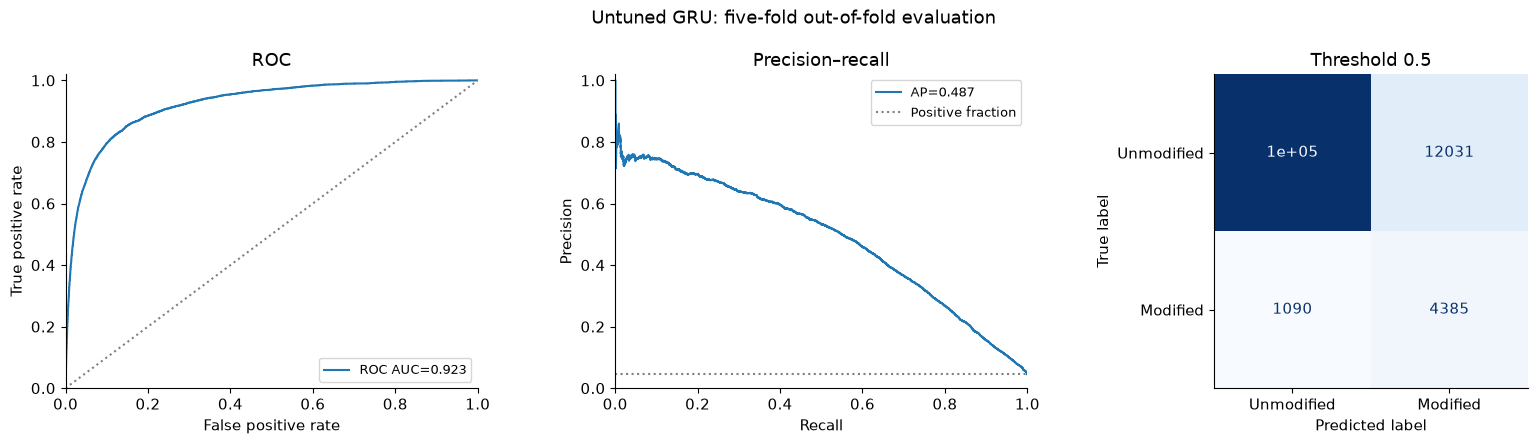

In [10]:
base_fold_metrics, base_oof_scores = run_cv(BASE_CONFIG, 'untuned_cv')
base_cv_summary = base_fold_metrics.drop(columns='fold').agg(['mean', 'std']).T
base_cv_summary.to_csv(RUN_DIR / 'untuned_cv_summary.csv')
display(base_fold_metrics.round(4))
display(base_cv_summary.round(4))
base_oof_metrics = metric_row(df.label.to_numpy(), base_oof_scores)
display(pd.DataFrame([base_oof_metrics], index=['Untuned pooled OOF']).round(4))
plot_evaluation(df.label.to_numpy(), base_oof_scores, 'Untuned GRU: five-fold out-of-fold evaluation',
                RUN_DIR / 'untuned_oof_evaluation.png')


## 8. Train on ALL data, then evaluate on ALL the same data
This is the requested full-data training and testing step. Every cleaned labelled row trains one final model; the same rows are scored afterward. The output is explicitly named **training resubstitution**. Use CV results to discuss unseen-fold performance, not this fitted-data score.

Scalers and class weights now legitimately use all rows because the deployment model trains on all rows. Save these scalers with the model; future inference must reuse them. No fold model is used as the final all-data model.


In [11]:
def fit_all_and_save(config, name):
    target = RUN_DIR / name
    target.mkdir(exist_ok=False)
    preprocessing = fit_preprocessing(df)
    seq, aux = transform(df, preprocessing)
    model, history = fit_model(seq, aux, df.label.to_numpy(dtype=np.float32), config, seed=SEED)
    scores = predict_scores(model, seq, aux)
    fitted_metrics = metric_row(df.label.to_numpy(), scores)
    history.to_csv(target / 'training_history.csv', index=False)
    pd.DataFrame([fitted_metrics]).to_csv(target / 'training_resubstitution_metrics.csv', index=False)
    output = df[KEY + ['label']].copy(); output['score'] = scores
    output.to_csv(target / 'training_resubstitution_predictions.csv.gz', index=False)
    output[KEY + ['score']].to_csv(target / 'all_data_scores.csv', index=False)
    checkpoint = {'state_dict': {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                  'config': config, 'threshold': THRESHOLD, 'position_columns': POSITION_COLUMNS}
    torch.save(checkpoint, target / 'rnn_model.pt')
    joblib.dump(preprocessing, target / 'preprocessing.joblib')
    (target / 'config.json').write_text(json.dumps(config, indent=2))
    print('Saved all-data model:', target)
    del seq, aux, model, preprocessing
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return target, fitted_metrics

base_model_dir, base_fitted_metrics = fit_all_and_save(BASE_CONFIG, 'untuned_all_data_model')
comparison = pd.DataFrame([base_oof_metrics, base_fitted_metrics],
    index=['Untuned OOF: unseen folds', 'Untuned training resubstitution: seen rows'])
display(comparison.round(4))
comparison.to_csv(RUN_DIR / 'untuned_oof_vs_training.csv')
FINAL_MODEL_DIR = base_model_dir


Epoch 01/20: loss=0.9279
Epoch 05/20: loss=0.6747
Epoch 10/20: loss=0.6414
Epoch 15/20: loss=0.6247
Epoch 20/20: loss=0.6027
Saved all-data model: D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\DSA4262-datahelix\data_cleaning\outputs\m6a_eda\20261005T115003_741688Z\rnn_cv_runs\20261006T051332_860200Z\untuned_all_data_model


,ROC_AUC,average_precision,PR_AUC_trapezoidal,precision,recall,F1,accuracy,balanced_accuracy,MCC
Untuned OOF: unseen folds,0.9230,0.4874,0.4872,0.2671,0.8009,0.4006,0.8923,0.8488,0.4232
Untuned training resubstitution: seen rows,0.9427,0.5278,0.5277,0.2468,0.8727,0.3848,0.8746,0.8737,0.4236


## 9. Hyperparameter tuning plan — separate second round
**Disabled by default for your first run.** Set `RUN_TUNING=True` below when ready, then run this section and subsequent cells. The first round above remains a distinct fixed-configuration experiment.

| Hyperparameter | Values searched | What it changes |
|---|---|---|
| GRU hidden size | 16, 32, 64 | Recurrent representation capacity |
| Dense-head dropout | 0.1, 0.3, 0.5 | Fraction of head activations dropped during training |
| Learning rate | 0.0003, 0.001, 0.003 | AdamW update step size |
| Weight decay | 0, 0.0001, 0.001 | AdamW parameter regularisation |
| Batch size | 128, 256 | Training examples per parameter update |
| Epochs | 15, 30 | Fixed training passes, including when fitting all data |
| Class weighting | True, False | Whether positive errors get training-fold inverse-frequency weighting |

**How tuned:** seeded `ParameterSampler` selects 6 distinct random combinations from the discrete Cartesian grid (648 total combinations). This is a small random search, not an exhaustive grid search and not a guarantee of finding the optimum. Each candidate gets the same five gene-disjoint folds, a fresh model per fold, and training-only scalers/weights. Select the highest **mean validation AP across the five folds**. The already-evaluated initial configuration is also eligible, so an inferior sampled candidate need not replace it. Exact ties retain the earlier configuration.

**Cost:** 6 configurations × 5 folds = 30 extra training runs, plus an all-data refit if a new configuration wins. The untuned first round requires 5 fold fits + 1 full-data fit.

**Interpretation:** the winning CV score is used for selection and can be optimistic. It is a *tuning result*, not an unbiased independent test result. Nested CV or a separate external labelled test would be needed for an independent assessment of the tuning procedure; neither is added here. The fixed first-round OOF result was obtained before tuning.


In [12]:
RUN_TUNING = False  # FIRST RUN: leave False. Set True for the separate tuning round.
N_RANDOM_TRIALS = 6
SEARCH_SPACE = {
    'hidden_size': [16, 32, 64], 'dropout': [0.1, 0.3, 0.5],
    'lr': [3e-4, 1e-3, 3e-3], 'weight_decay': [0.0, 1e-4, 1e-3],
    'batch_size': [128, 256], 'epochs': [15, 30], 'class_weighting': [True, False],
}
# Search occurs only below; defining candidate values does not tune the first round.
search_results = None
selected_config = dict(BASE_CONFIG)
selected_name = 'untuned_reference'
selected_fold_metrics = base_fold_metrics
selected_oof_scores = base_oof_scores
if RUN_TUNING:
    candidates = list(ParameterSampler(SEARCH_SPACE, n_iter=N_RANDOM_TRIALS, random_state=SEED))
    records = [{'trial': 'untuned_reference', **BASE_CONFIG,
                'mean_cv_AP': base_fold_metrics.average_precision.mean(),
                'std_cv_AP': base_fold_metrics.average_precision.std()}]
    best_score = float(records[0]['mean_cv_AP'])
    for trial, config in enumerate(candidates, 1):
        name = f'tuning_trial_{trial:02d}'
        print(f'\n{name}: {config}', flush=True)
        fold_metrics, oof_scores = run_cv(config, name)
        mean_ap = float(fold_metrics.average_precision.mean())
        records.append({'trial': name, **config, 'mean_cv_AP': mean_ap,
                        'std_cv_AP': float(fold_metrics.average_precision.std())})
        # Save partial results after each trial so completed work remains inspectable.
        pd.DataFrame(records).to_csv(RUN_DIR / 'tuning_results.csv', index=False)
        if mean_ap > best_score:
            best_score, selected_name = mean_ap, name
            selected_config = dict(config)
            selected_fold_metrics, selected_oof_scores = fold_metrics, oof_scores
    search_results = pd.DataFrame(records).sort_values('mean_cv_AP', ascending=False, kind='stable')
    display(search_results)
    print('Selected:', selected_name, selected_config)
    (RUN_DIR / 'selected_config.json').write_text(json.dumps(selected_config, indent=2))
else:
    print('Tuning skipped. The fixed first-round all-data model remains the final model.')


Tuning skipped. The fixed first-round all-data model remains the final model.


## 10. Review tuning results and refit the selected model on ALL data
If tuning is enabled, plot mean fold AP (error bars = fold SD, not confidence intervals), then fit the winner on all rows and evaluate the same rows. If the untuned reference wins, reuse its identical saved all-data fit. CV folds are never permanently held out of this final fit.


In [13]:
if RUN_TUNING:
    ranked = search_results.sort_values('mean_cv_AP')
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(ranked.trial, ranked.mean_cv_AP, xerr=ranked.std_cv_AP, color='#356995', capsize=3)
    ax.set(xlim=(0, 1), xlabel='Mean five-fold validation AP (error bars: fold SD)',
           ylabel='Configuration', title='Hyperparameter selection results — not independent test scores')
    fig.tight_layout(); fig.savefig(RUN_DIR / 'tuning_comparison.png', dpi=150); plt.show()
    if selected_name == 'untuned_reference':
        FINAL_MODEL_DIR, selected_fitted_metrics = base_model_dir, base_fitted_metrics
    else:
        FINAL_MODEL_DIR, selected_fitted_metrics = fit_all_and_save(selected_config, 'selected_all_data_model')
    selected_summary = pd.DataFrame([
        metric_row(df.label.to_numpy(), selected_oof_scores), selected_fitted_metrics],
        index=['Selected pooled OOF: used for tuning', 'Selected training resubstitution: seen rows'])
    display(selected_summary.round(4))
    selected_summary.to_csv(RUN_DIR / 'selected_oof_vs_training.csv')
print('Final all-data model directory:', FINAL_MODEL_DIR)


Final all-data model directory: D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\DSA4262-datahelix\data_cleaning\outputs\m6a_eda\20261005T115003_741688Z\rnn_cv_runs\20261006T051332_860200Z\untuned_all_data_model


## 11. Reload and predict new cleaned data
The function needs the same cleaned summaries, sequence and coverage; no labels or gene IDs are needed for prediction. It returns exactly `transcript_id,transcript_position,score`. Preprocessing is loaded from disk and never refitted.

The project requires predictions from raw JSON. Reuse the cleaner's exact feature extraction for unseen JSON, then call this predictor. QC-passing `clean_signal_sites.csv.gz` may omit quarantined raw sites: reconcile all original keys and define/report an exclusion policy before submitting. This notebook does not invent fallback predictions or replace the required standalone raw-JSON prediction script. Only load trusted PyTorch/joblib files.


In [14]:
def load_predictor(model_dir):
    model_dir = Path(model_dir)
    saved = torch.load(model_dir / 'rnn_model.pt', map_location='cpu', weights_only=True)
    if saved['position_columns'] != POSITION_COLUMNS: raise ValueError('Feature-order mismatch.')
    model = SiteGRU(saved['config']['hidden_size'], saved['config']['dropout']).to(DEVICE)
    model.load_state_dict(saved['state_dict']); model.eval()
    return model, joblib.load(model_dir / 'preprocessing.joblib')

def predict_cleaned_sites(frame, model, preprocessing):
    validate_features(frame)
    seq, aux = transform(frame, preprocessing)
    output = frame[KEY].copy()
    output['transcript_position'] = output.transcript_position.astype('int64')
    output['score'] = predict_scores(model, seq, aux)
    if not np.isfinite(output.score).all() or not output.score.between(0, 1).all():
        raise ValueError('Invalid predicted scores.')
    return output

model, preprocessing = load_predictor(FINAL_MODEL_DIR)
reloaded_preview = predict_cleaned_sites(df.head(32), model, preprocessing)
saved_preview = pd.read_csv(FINAL_MODEL_DIR / 'training_resubstitution_predictions.csv.gz', nrows=32)
np.testing.assert_allclose(reloaded_preview.score, saved_preview.score, rtol=1e-5, atol=1e-6)
print('Save/reload consistency check passed.')
display(reloaded_preview.head(10))

# Optional: predict a genuinely unseen dataset after applying identical extraction.
# unseen = pd.read_csv('/CHANGE/TO/unseen/clean_signal_sites.csv.gz', dtype={'transcript_id': str})
# predictions = predict_cleaned_sites(unseen, model, preprocessing)
# predictions.to_csv(RUN_DIR / 'unseen_predictions.csv', index=False)


Save/reload consistency check passed.


,transcript_id,transcript_position,score
0,ENST00000000233,244,0.042903
1,ENST00000000233,261,0.520510
2,ENST00000000233,316,0.001734
3,ENST00000000233,332,0.382340
4,ENST00000000233,368,0.005191
5,ENST00000000233,404,0.099572
6,ENST00000000233,431,0.053745
7,ENST00000000233,440,0.031835
8,ENST00000000233,471,0.468499
9,ENST00000000233,539,0.364511


## 12. Save the reproducibility record


In [15]:
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''): digest.update(block)
    return digest.hexdigest()

metadata = {'input_path': str(CLEAN_FILE.resolve()), 'input_sha256': sha256_file(CLEAN_FILE),
    'eda_manifest': eda_manifest, 'seed': SEED, 'n_folds': N_FOLDS,
    'fold_assignment_sha256': sha256_file(RUN_DIR / 'cv_fold_assignments.csv.gz'),
    'splitter': 'StratifiedGroupKFold grouped by gene_id', 'permanent_test_holdout': False,
    'threshold': THRESHOLD, 'early_stopping': False, 'base_config': BASE_CONFIG,
    'tuning_enabled': RUN_TUNING, 'search_space': SEARCH_SPACE,
    'random_trials': N_RANDOM_TRIALS if RUN_TUNING else 0,
    'selection_metric': 'mean fold average precision', 'selected_config': selected_config,
    'final_model_directory': str(FINAL_MODEL_DIR.resolve()),
    'position_columns': POSITION_COLUMNS,
    'auxiliary_features': 'seven ACGT one-hot bases position-first; scaled log1p coverage',
    'python': sys.version, 'device': str(DEVICE),
    'packages': {p: importlib.metadata.version(p) for p in
                 ['numpy','pandas','scikit-learn','matplotlib','torch','joblib']}}
(RUN_DIR / 'run_metadata.json').write_text(json.dumps(metadata, indent=2))
(RUN_DIR / 'requirements_used.txt').write_text('\n'.join(f'{p}=={v}' for p,v in metadata['packages'].items())+'\n')
print('Outputs:', RUN_DIR.resolve())


Outputs: D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\DSA4262-datahelix\data_cleaning\outputs\m6a_eda\20261005T115003_741688Z\rnn_cv_runs\20261006T051332_860200Z


## Run and interpretation checklist
- Set `CLEAN_DIR`; use **Restart Kernel → Run All**. Leave `RUN_TUNING=False` for the initial untuned experiment. Inspect five fold counts, CV tables, OOF plots, and model save/reload consistency.
- For tuning afterward, set `RUN_TUNING=True` and run sections 9–12. Rerunning a completed training section in the same session encounters existing experiment folders; restart and run all to create a new output directory if needed.
- Summarise **untuned fold mean ± SD**, pooled OOF metrics, and **all-data training resubstitution metrics** separately. Do not present the latter as independent testing.
- The selected tuning score reuses folds for selection and is optimistic; label it accordingly. External labels or nested CV are needed for independent tuned-model evaluation.
- This notebook intentionally reserves no test set. All data trains the final model. If official unseen evaluation data arrives, use the saved model and scalers without fitting to that evaluation data.
- Compare with a simple baseline and m6Anet on compatible evaluation sets for the handout. Add the documented training and raw-JSON prediction scripts to your repository.
- File size alone cannot determine runtime. With your 600 MB input, inspect the printed DataFrame memory and Task Manager during preprocessing. The GRU is small, but 30 extra tuning fits can take much longer than the initial six fits.

**Authoring checks:** Python cell syntax, five-fold membership/disjointness, positional mapping, training-only preprocessing and metric calculations can be checked without your data. Full PyTorch training and visual inspection of result plots still need to be completed on your machine; real-data performance is unknown.
